<a href="https://colab.research.google.com/github/vibzium/coffee_sales/blob/main/Final_coffee_sale.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
   for filename in filenames:
    print(os.path.join(dirname, filename))

In [ ]:
# Load the dataset
coffee_sales = pd.read_csv('/content/index.csv')

In [ ]:
# Display the first 5 rows
coffee_sales.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


In [ ]:
coffee_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1133 entries, 0 to 1132
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         1133 non-null   object 
 1   datetime     1133 non-null   object 
 2   cash_type    1133 non-null   object 
 3   card         1044 non-null   object 
 4   money        1133 non-null   float64
 5   coffee_name  1133 non-null   object 
dtypes: float64(1), object(5)
memory usage: 53.2+ KB


In [ ]:
data_missing = coffee_sales.isnull().sum()
data_missing

,0
date,0
datetime,0
cash_type,0
card,89
money,0
coffee_name,0


In [ ]:
coffee_sales.duplicated().sum()

np.int64(0)

In [ ]:
# Replace missing values in the 'card' column with 'Unknown'
coffee_sales['card'].fillna('Cash Paymnet', inplace=True)

# Verify that there are no more missing values
missing_data_after_cleaning = coffee_sales.isnull().sum()

missing_data_after_cleaning

,0
date,0
datetime,0
cash_type,0
card,0
money,0
coffee_name,0


In [ ]:
# 2. Outlier Detection in the 'money' column using Interquartile Range (IQR)
Q1 = coffee_sales['money'].quantile(0.25)
Q3 = coffee_sales['money'].quantile(0.75)
IQR = Q3 - Q1

# Determine the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = coffee_sales[(coffee_sales['money'] < lower_bound) | (coffee_sales['money'] > upper_bound)]

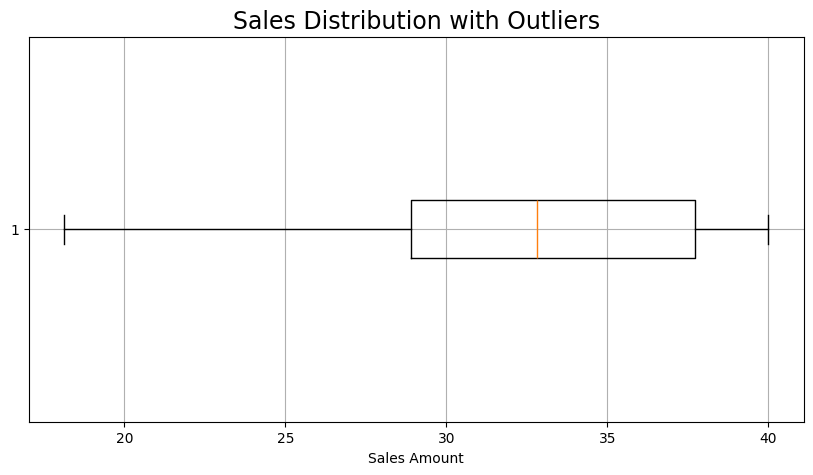

In [ ]:
# Visualize sales distribution with outliers using a boxplot
plt.figure(figsize=(10, 5))
plt.boxplot(coffee_sales['money'], vert=False)
plt.title('Sales Distribution with Outliers',fontsize=17)
plt.xlabel('Sales Amount')
plt.grid(True)
plt.show()

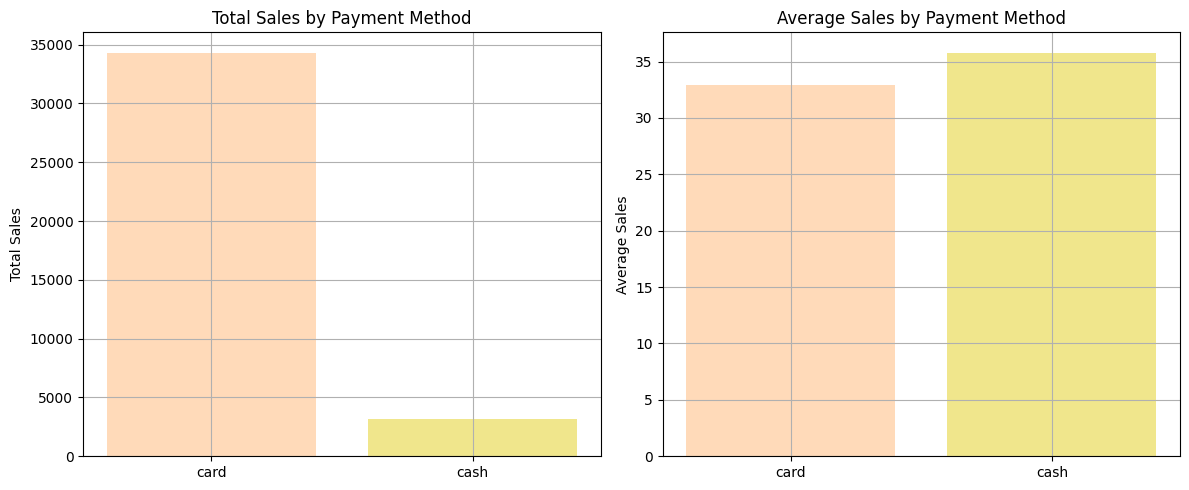

In [ ]:
# 3. Review the impact of payment method (Cash vs. Card)
# Aggregate sales by payment method
payment_method_sales = coffee_sales.groupby('cash_type')['money'].sum()
average_payment_method_sales = coffee_sales.groupby('cash_type')['money'].mean()

# Visualization of the impact of payment method
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Total sales by payment method
ax[0].bar(payment_method_sales.index, payment_method_sales, color=['peachpuff', 'khaki'])
ax[0].set_title('Total Sales by Payment Method')
ax[0].set_ylabel('Total Sales')
ax[0].grid(True)

# Average sales by payment method
ax[1].bar(average_payment_method_sales.index, average_payment_method_sales, color=['peachpuff', 'khaki'])
ax[1].set_title('Average Sales by Payment Method')
ax[1].set_ylabel('Average Sales')
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Display summary of outliers and payment method impact
outliers_summary = outliers.describe()
payment_method_sales, average_payment_method_sales, outliers_summary

(cash_type
 card    34322.88
 cash     3186.00
 Name: money, dtype: float64,
 cash_type
 card    32.876322
 cash    35.797753
 Name: money, dtype: float64,
        money
 count    0.0
 mean     NaN
 std      NaN
 min      NaN
 25%      NaN
 50%      NaN
 75%      NaN
 max      NaN)

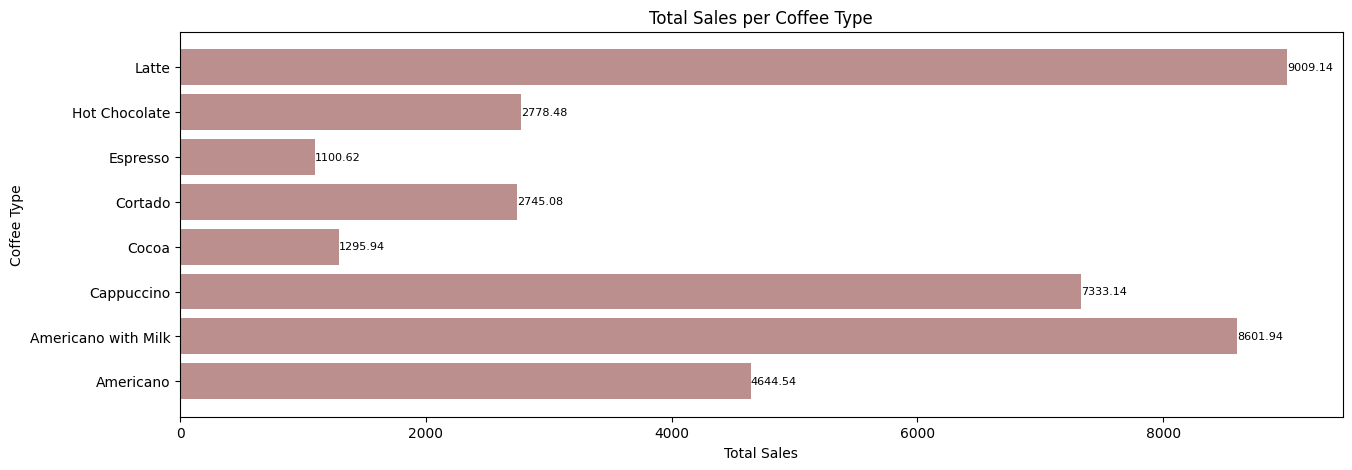

In [ ]:
# Distribution per Coffee Type
coffee_type_sales = coffee_sales.groupby('coffee_name')['money'].sum()

# Visualize the distribution
plt.figure(figsize=(15, 5))
plt.barh(coffee_type_sales.index, coffee_type_sales.values, color='rosybrown')
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=8)
plt.title('Total Sales per Coffee Type')
plt.xlabel('Total Sales')
plt.ylabel('Coffee Type')
plt.show()

In [ ]:
# Convert 'datetime' column to datetime objects
coffee_sales['datetime'] = pd.to_datetime(coffee_sales['datetime'])

# Extract the hour from 'datetime' to analyze distribution by time of day
coffee_sales['hour'] = coffee_sales['datetime'].dt.hour
purchasing_time_distribution = coffee_sales.groupby('hour')['money'].sum()

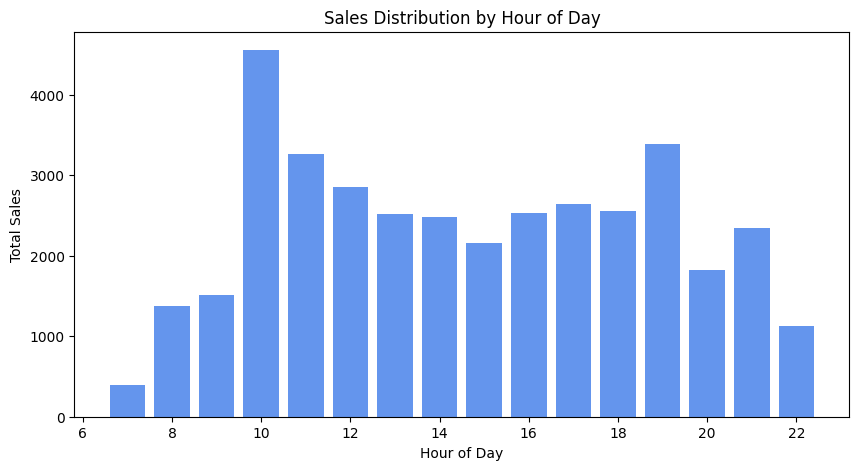

In [ ]:
# Visualize the distribution per purchasing time
plt.figure(figsize=(10, 5))
plt.bar(purchasing_time_distribution.index, purchasing_time_distribution.values, color='cornflowerblue')
plt.title('Sales Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
# Extract the month name and number for proper sorting
coffee_sales['month'] = coffee_sales['datetime'].dt.month
coffee_sales['month_name'] = coffee_sales['datetime'].dt.month_name()

# Aggregate sales by month number
monthly_sales = coffee_sales.groupby('month').agg(
    total_sales=('money', 'sum'),
    month_name=('month_name', 'first')  # to keep the month name
)

# Sort by month number (ascending calendar order)
monthly_sales = monthly_sales.sort_index()

# Set month name as index for better readability
monthly_sales.set_index('month_name', inplace=True)

# Display the monthly sales
display(monthly_sales['total_sales'])

,total_sales
month_name,
March,7050.20
April,6720.56
May,9063.42
June,7758.76
July,6915.94


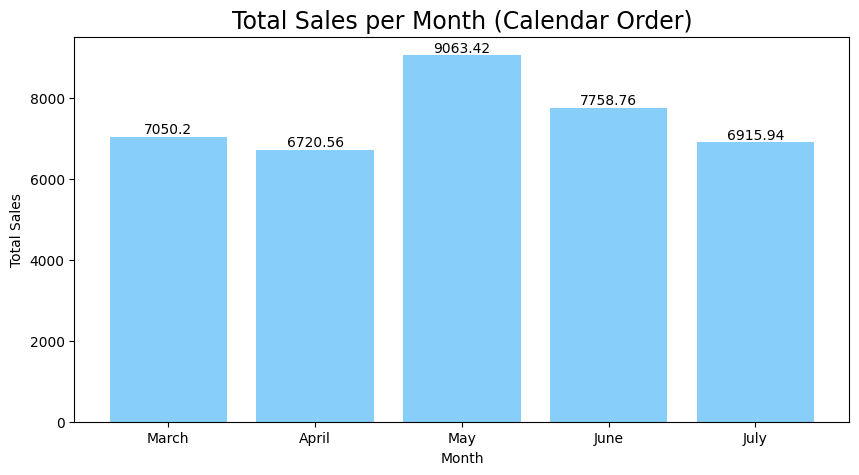

In [ ]:
# Sort the monthly sales by calendar order
monthly_sales_calendar = monthly_sales['total_sales']  # already indexed by month name and sorted by month number

# Plot monthly-wise bar chart
plt.figure(figsize=(10, 5))
plt.bar(monthly_sales_calendar.index, monthly_sales_calendar.values, color='lightskyblue')
plt.title('Total Sales per Month (Calendar Order)',fontsize=17)
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=10)
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
# Cash Money vs Card Money
cash_vs_card_sales = coffee_sales.groupby('cash_type')['money'].sum()

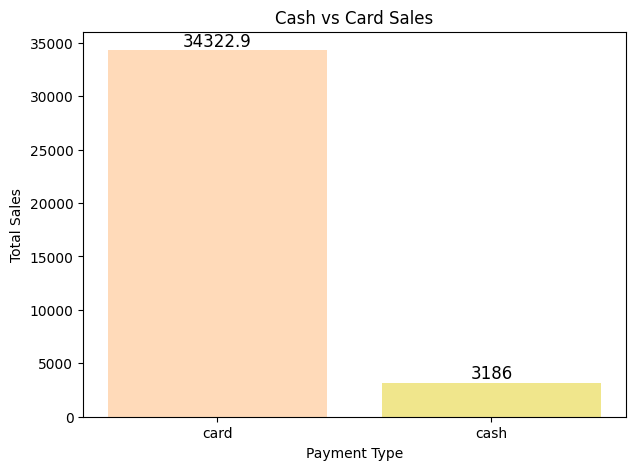

,money
cash_type,
card,34322.88
cash,3186.00


In [ ]:
# Visualize Cash vs Card Sales
plt.figure(figsize=(7, 5))
plt.bar(cash_vs_card_sales.index, cash_vs_card_sales.values, color=['peachpuff', 'khaki'])
plt.title('Cash vs Card Sales')
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=12)
plt.xlabel('Payment Type')
plt.ylabel('Total Sales')
plt.show()

# Display cash vs card sales
cash_vs_card_sales

In [ ]:
# Ensure datetime column is datetime type and is a column
# Reset index to make 'datetime' a column again if it was set as index previously
if isinstance(coffee_sales.index, pd.DatetimeIndex):
    coffee_sales = coffee_sales.reset_index()

coffee_sales['datetime'] = pd.to_datetime(coffee_sales['datetime'])

# Extract ISO week number
coffee_sales['week'] = coffee_sales['datetime'].dt.isocalendar().week

# Group by week number (1–52/53), combining across all years
weekly_sales = coffee_sales.groupby('week')['money'].sum()

# Display weekly sales
display(weekly_sales)

,money
week,
9,973.50
10,1840.50
11,1516.30
12,1307.80
13,1412.10
14,1434.50
15,1666.00
16,1838.84
17,1251.20


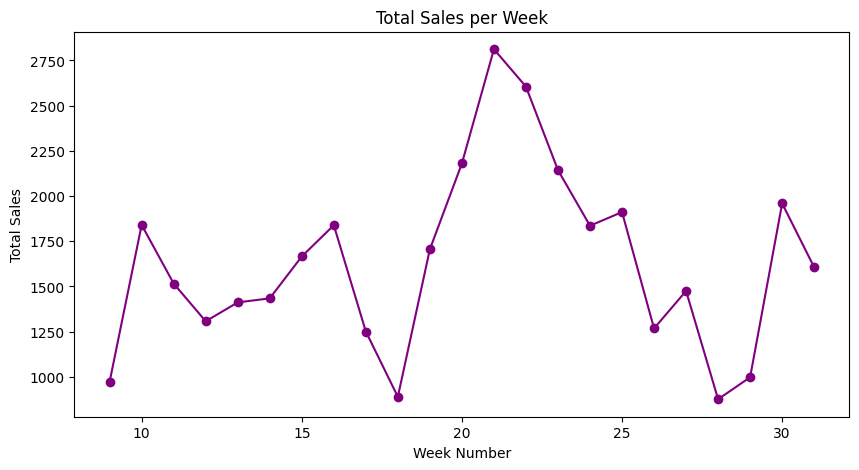

In [ ]:
# Visualize weekly sales
plt.figure(figsize=(10, 5))
plt.plot(weekly_sales.index, weekly_sales.values, marker='o', color='purple')
plt.title('Total Sales per Week')
plt.xlabel('Week Number')
plt.ylabel('Total Sales')
plt.show()

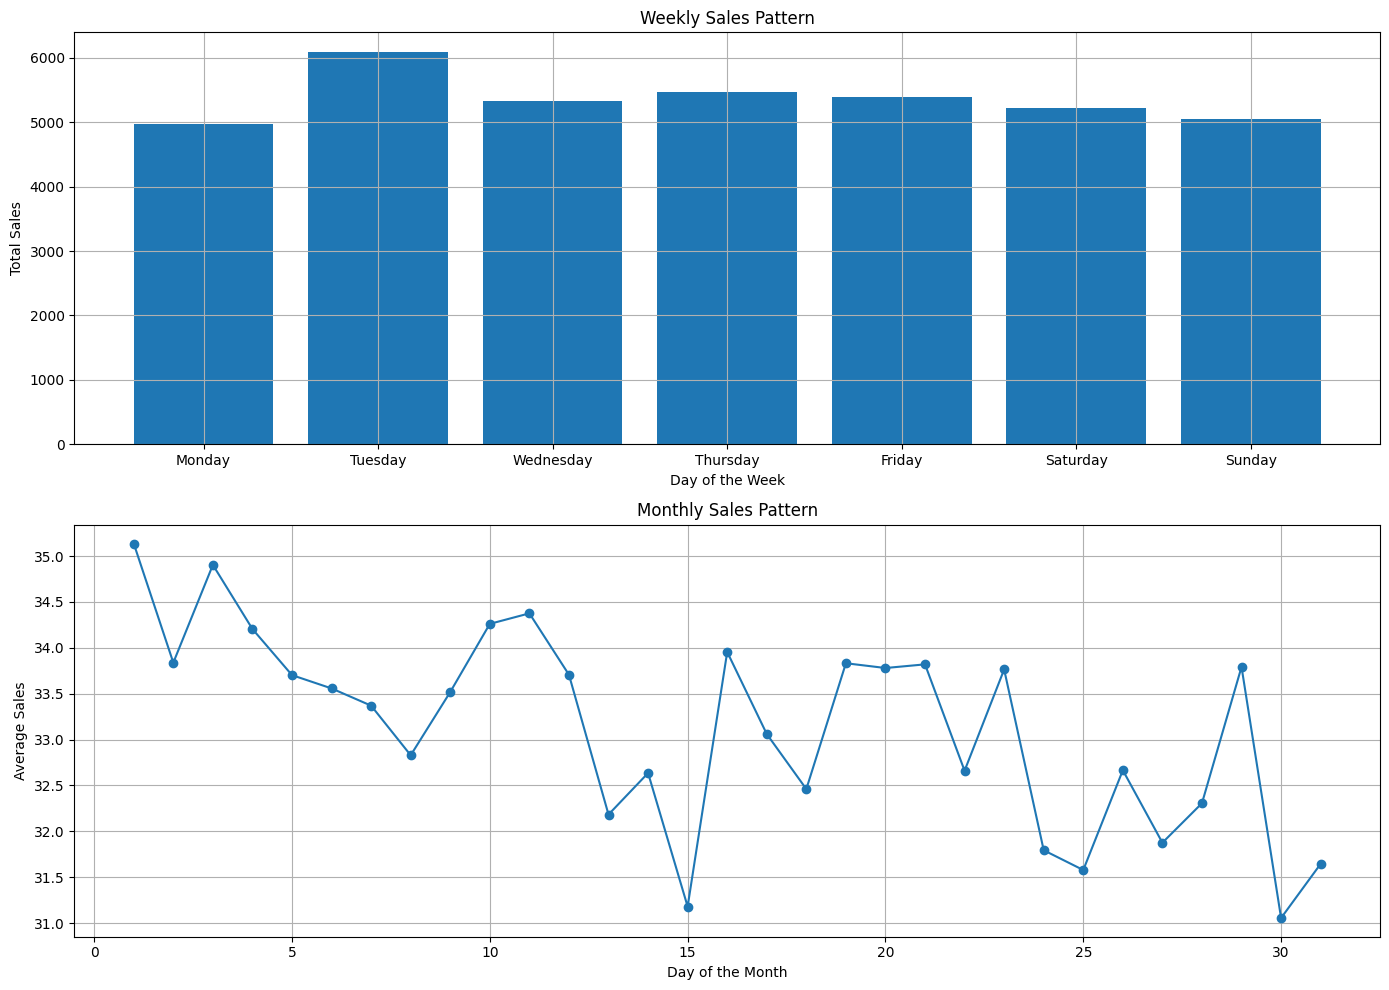

In [ ]:
# Set 'datetime' as index
coffee_sales = coffee_sales.set_index('datetime')

# 1. Weekly Seasonality Analysis
# Aggregate sales by day of the week
coffee_sales['day_of_week'] = coffee_sales.index.day_name()
weekly_sales = coffee_sales.groupby('day_of_week')['money'].sum()

# Order days of the week for visualization
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_sales = weekly_sales.reindex(ordered_days)

# 2. Monthly Seasonality Analysis
# Aggregate sales by day of the month
coffee_sales['day_of_month'] = coffee_sales.index.day
monthly_sales = coffee_sales.groupby('day_of_month')['money'].mean()

# 3. Visualizations for Seasonal Patterns
fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# Plot weekly sales pattern
ax[0].bar(weekly_sales.index, weekly_sales)
ax[0].set_title('Weekly Sales Pattern')
ax[0].set_xlabel('Day of the Week')
ax[0].set_ylabel('Total Sales')
ax[0].grid(True)

# Plot monthly sales pattern
ax[1].plot(monthly_sales.index, monthly_sales, marker='o')
ax[1].set_title('Monthly Sales Pattern')
ax[1].set_xlabel('Day of the Month')
ax[1].set_ylabel('Average Sales')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Sales per day
daily_sales = coffee_sales['money'].resample('D').sum()

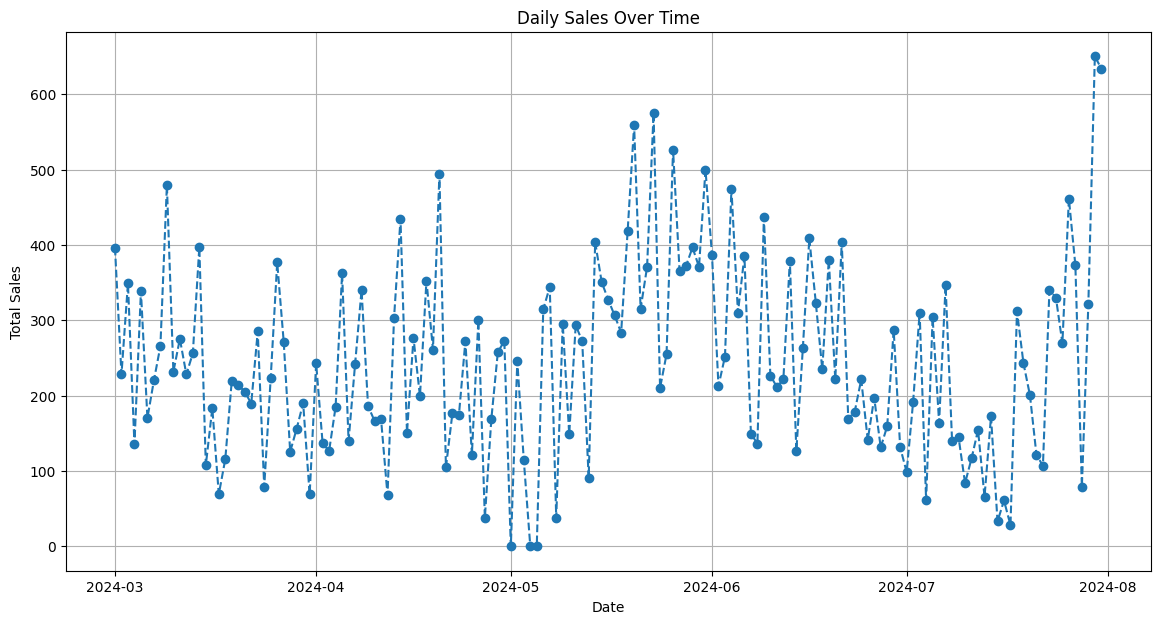

datetime
2024-03-01    396.30
2024-03-02    228.10
2024-03-03    349.10
2024-03-04    135.20
2024-03-05    338.50
               ...  
2024-07-27    372.76
2024-07-28     78.86
2024-07-29    321.82
2024-07-30    650.48
2024-07-31    633.84
Freq: D, Name: money, Length: 153, dtype: float64


In [ ]:
# Plot the daily sales to explore trends over time
plt.figure(figsize=(14, 7))
plt.plot(daily_sales, marker='o', linestyle='--')
plt.title('Daily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

print(daily_sales.head(153))

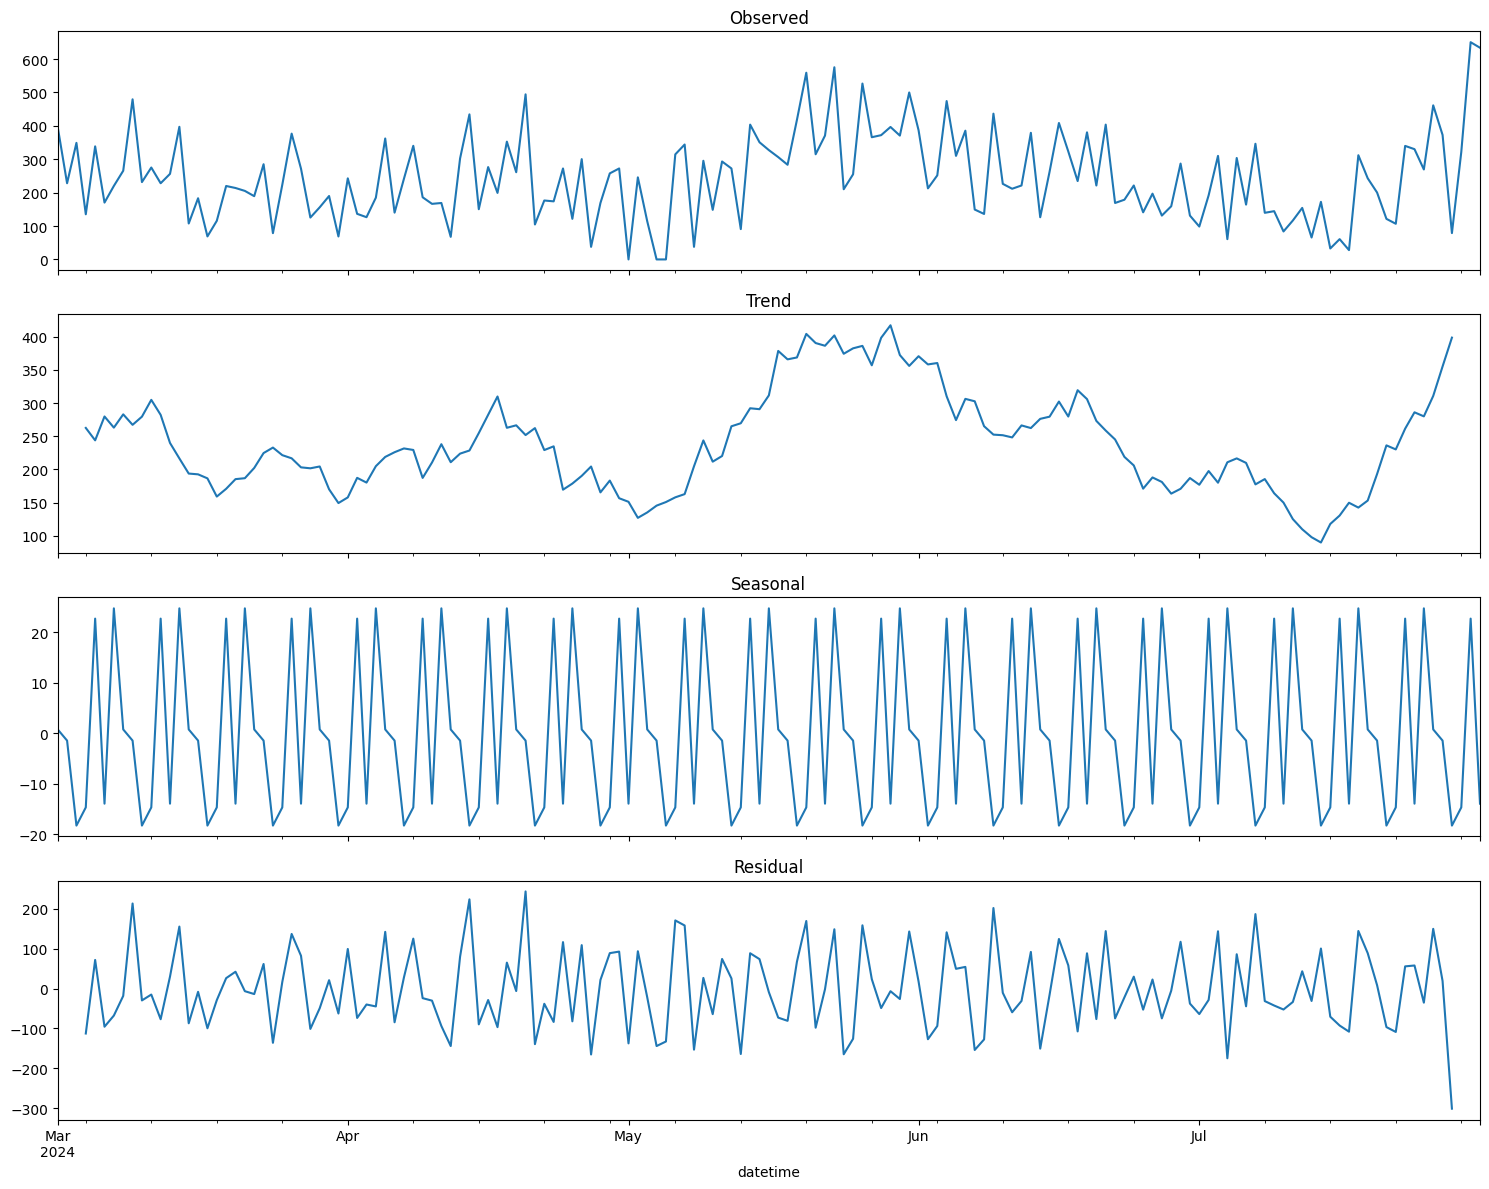

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform seasonal decomposition
decomposition = seasonal_decompose(daily_sales, model='additive', period=7)  # Assuming weekly seasonality

# Plot the decomposed components
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(15, 12), sharex=True)
decomposition.observed.plot(ax=ax1, title='Observed')
decomposition.trend.plot(ax=ax2, title='Trend')
decomposition.seasonal.plot(ax=ax3, title='Seasonal')
decomposition.resid.plot(ax=ax4, title='Residual')

plt.tight_layout()
plt.show()

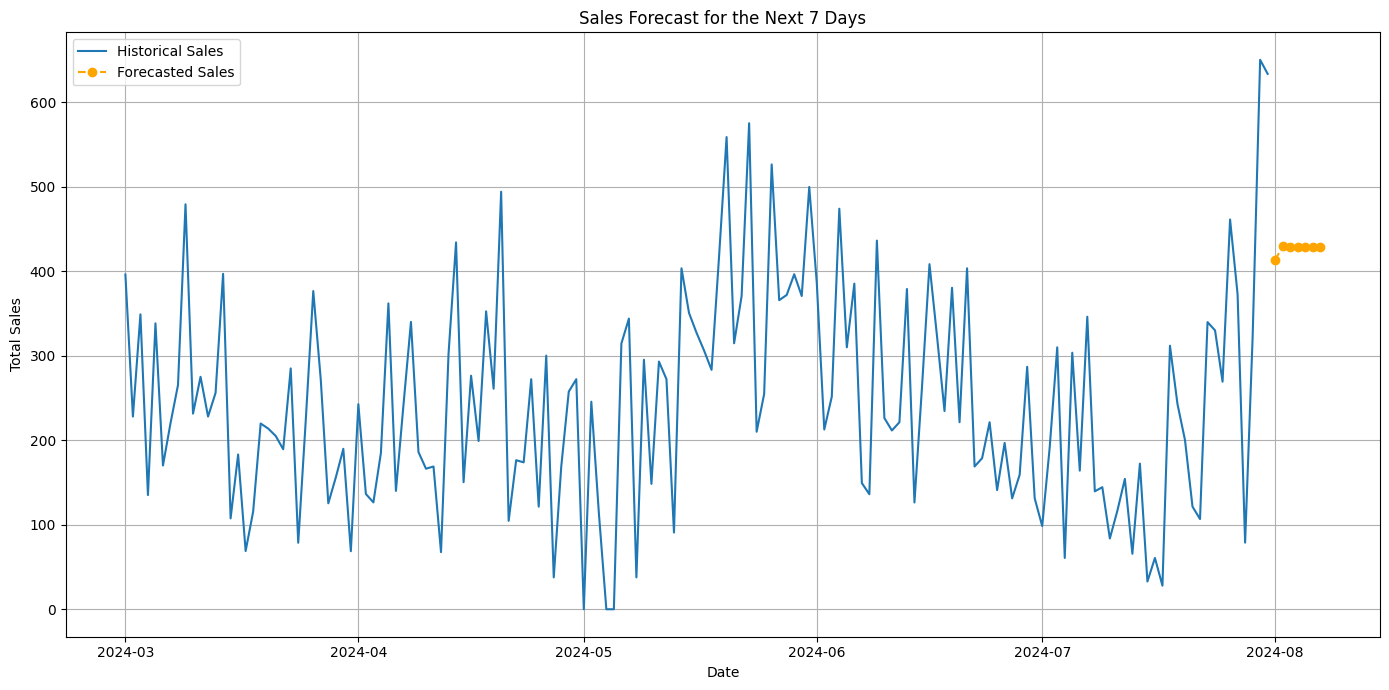

,predicted_mean
2024-08-01,413.709119
2024-08-02,429.494876
2024-08-03,428.362867
2024-08-04,428.444044
2024-08-05,428.438223
2024-08-06,428.438641
2024-08-07,428.438611


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Ensure daily_sales has a DatetimeIndex
daily_sales = daily_sales.asfreq('D')  # Set frequency to daily

# Fit an ARIMA model (p,d,q) = (1,1,1) as a starting point
arima_model = ARIMA(daily_sales, order=(1, 1, 1))
arima_fit = arima_model.fit()

# Forecast the next 7 days
forecast = arima_fit.forecast(steps=7)

# Create a proper datetime index for the forecast
last_date = daily_sales.index[-1]
forecast_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=7, freq='D')
forecast = pd.Series(forecast, index=forecast_index)

# Plot historical and forecasted sales
plt.figure(figsize=(14, 7))
plt.plot(daily_sales, label='Historical Sales')
plt.plot(forecast.index, forecast, label='Forecasted Sales', linestyle='--', marker='o', color='orange')
plt.title('Sales Forecast for the Next 7 Days')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

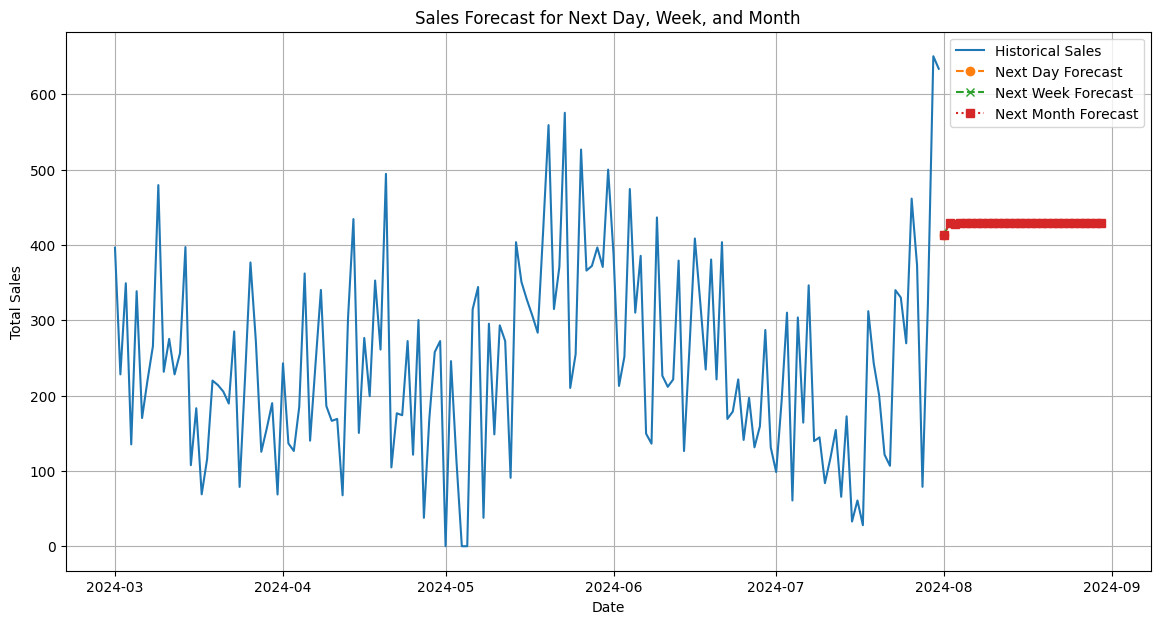

In [ ]:
# Extend ARIMA forecasting to predict next day, week, and month sales

# Forecast the next day (1 step ahead)
next_day_forecast = arima_fit.forecast(steps=1)

# Forecast the next week (7 days ahead)
next_week_forecast = arima_fit.forecast(steps=7)

# Forecast the next month (30 days ahead)
next_month_forecast = arima_fit.forecast(steps=30)

# Create datetime index for forecasts
last_date = daily_sales.index[-1]
next_day_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=1, freq='D')
next_week_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=7, freq='D')
next_month_index = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=30, freq='D')

# Plot the historical sales data along with the forecasts
plt.figure(figsize=(14, 7))
plt.plot(daily_sales, label='Historical Sales')
plt.plot(next_day_forecast.index, next_day_forecast, label='Next Day Forecast', marker='o', linestyle='--')
plt.plot(next_week_forecast.index, next_week_forecast, label='Next Week Forecast', marker='x', linestyle='--')
plt.plot(next_month_forecast.index, next_month_forecast, label='Next Month Forecast', linestyle=':', marker='s')
plt.title('Sales Forecast for Next Day, Week, and Month')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)
plt.show()

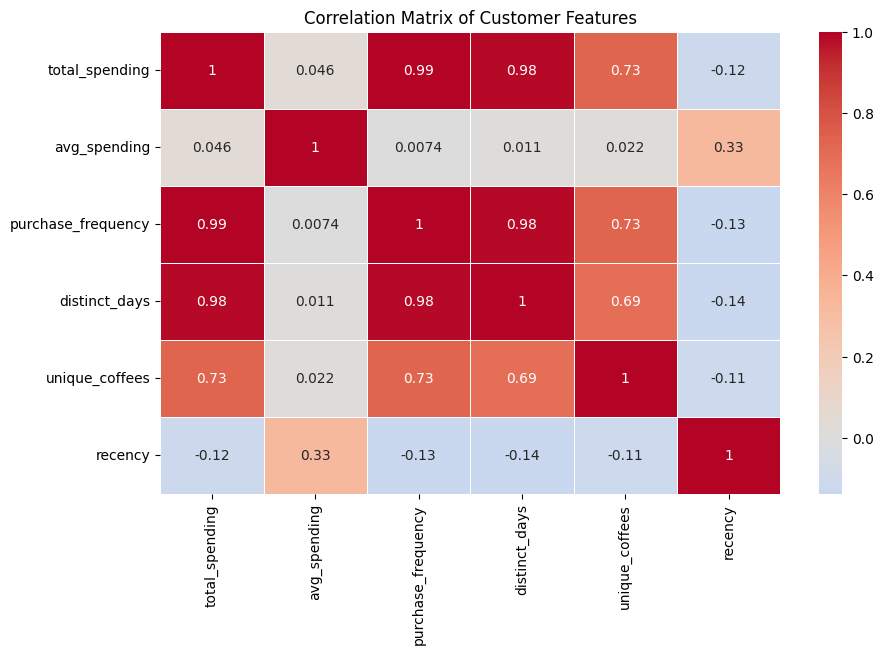

,total_spending,avg_spending,purchase_frequency,distinct_days,unique_coffees,recency
total_spending,1.000000,0.045674,0.994912,0.984794,0.729213,-0.116179
avg_spending,0.045674,1.000000,0.007374,0.011410,0.021728,0.325301
purchase_frequency,0.994912,0.007374,1.000000,0.982740,0.727147,-0.131916
distinct_days,0.984794,0.011410,0.982740,1.000000,0.691335,-0.138129
unique_coffees,0.729213,0.021728,0.727147,0.691335,1.000000,-0.109703
recency,-0.116179,0.325301,-0.131916,-0.138129,-0.109703,1.000000


In [ ]:
# Ensure datetime is in the correct format and is a column
coffee_sales_reset = coffee_sales.copy()
if isinstance(coffee_sales_reset.index, pd.DatetimeIndex):
    coffee_sales_reset = coffee_sales_reset.reset_index()
coffee_sales_reset['datetime'] = pd.to_datetime(coffee_sales_reset['datetime'])


# Recreate the customer_features_enhanced DataFrame with the correct recency calculation
customer_features_enhanced = coffee_sales_reset.groupby('card').agg(
    total_spending=('money', 'sum'),
    avg_spending=('money', 'mean'),
    purchase_frequency=('money', 'count'),
    distinct_days=('datetime', lambda x: x.dt.date.nunique()), # Calculate distinct days using the Series
    unique_coffees=('coffee_name', 'nunique'),
    recency=('datetime', lambda x: (coffee_sales_reset['datetime'].max().date() - x.max().date()).days) # Calculate recency using the Series from the reset dataframe
).reset_index()


# Perform correlation analysis
correlation_features = customer_features_enhanced[['total_spending', 'avg_spending', 'purchase_frequency',
                                                   'distinct_days', 'unique_coffees', 'recency']]

# Calculate the correlation matrix
correlation_matrix = correlation_features.corr()

# Visualize the correlation matrix using a heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Matrix of Customer Features')
plt.show()

# Display the correlation matrix
display(correlation_matrix)

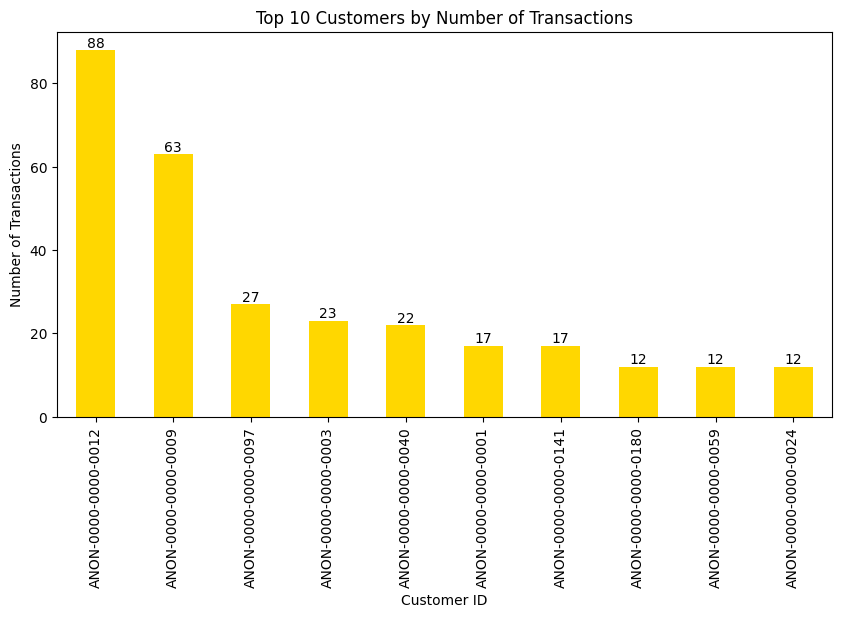

In [ ]:
# Filter only card transactions
card_sales = coffee_sales[coffee_sales['cash_type'] == 'card']

# Top Customers by Number of Card Transactions
top_customers = card_sales['card'].value_counts().head(10)

# Visualize the top customers
plt.figure(figsize=(10, 5))
top_customers.plot(kind='bar', color='gold')
plt.title('Top 10 Customers by Number of Transactions')
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=10)
plt.xlabel('Customer ID')
plt.ylabel('Number of Transactions')
plt.show()

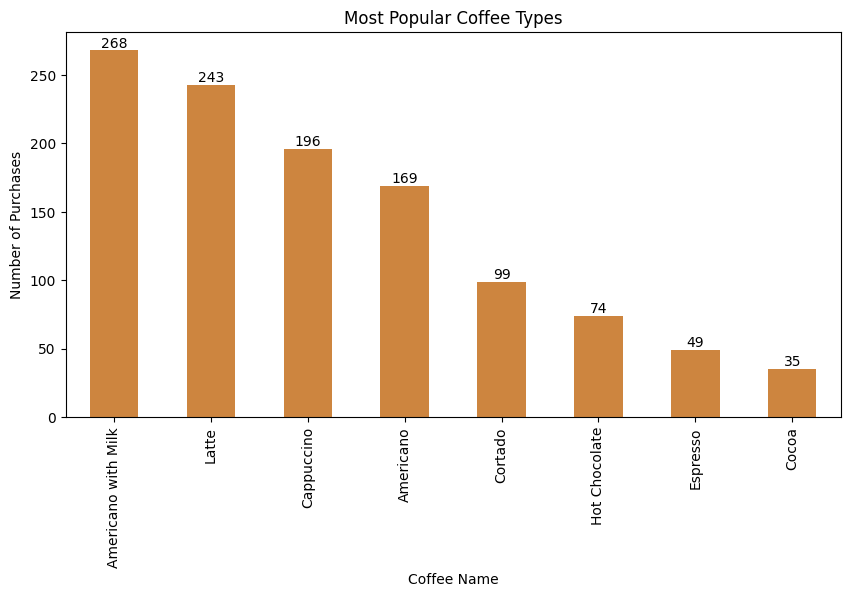

In [ ]:
# Popular Coffee Types
popular_coffees = coffee_sales['coffee_name'].value_counts()

# Visualize the most popular coffee types
plt.figure(figsize=(10, 5))
popular_coffees.plot(kind='bar', color='peru')
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=10)
plt.title('Most Popular Coffee Types')
plt.xlabel('Coffee Name')
plt.ylabel('Number of Purchases')
plt.show()

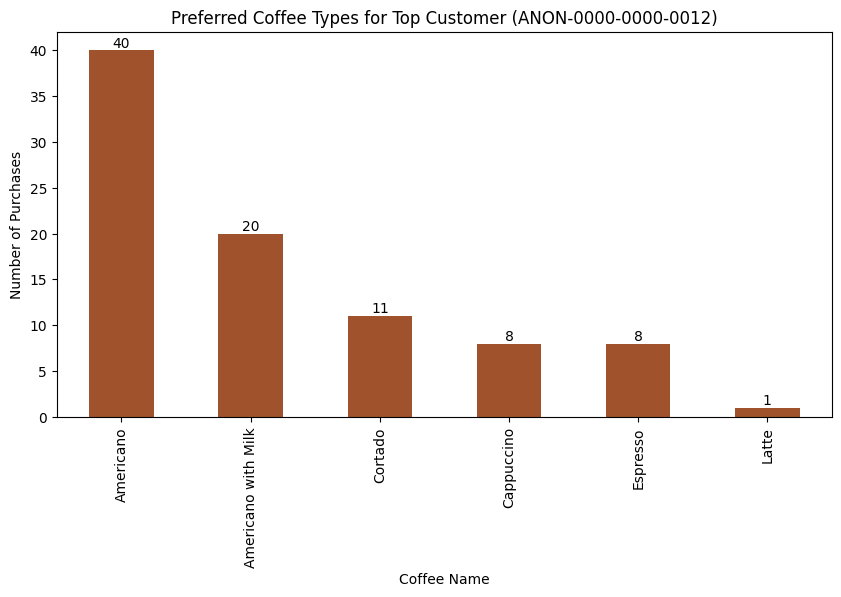

In [ ]:
# Analyze Purchasing Patterns for the Top Customer
top_customer_id = top_customers.index[0]
top_customer_purchases = coffee_sales[coffee_sales['card'] == top_customer_id]['coffee_name'].value_counts()

# Visualize the preferred coffee types for the top customer
plt.figure(figsize=(10, 5))
top_customer_purchases.plot(kind='bar', color='sienna')
plt.title(f'Preferred Coffee Types for Top Customer ({top_customer_id})')
ax = plt.gca()
ax.bar_label(ax.containers[0], fontsize=10)
plt.xlabel('Coffee Name')
plt.ylabel('Number of Purchases')
plt.show()